# ML-10 — Content Action Playbook

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Devaaldo/flyrank-ml/blob/main/work/notebooks/w07_action_playbook.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Ranked actions + reason codes

*The queue: what to do first, and why, in words a human trusts.*

### 1. From Validated Model to Operational Playbook
In Week 5 (ML-08) and Week 6 (ML-09), our client-holdout validation established that an L2-regularized **Logistic Regression** model provided the most reliable, monotonic ranking on unseen client domains, achieving a measured **76.0% Precision@50** (versus 42.0% for heuristic rules and 46.0% for overfit tree ensembles).

However, in production, handing an editorial team raw decay probabilities ($P(\text{decay})$) is insufficient. Editorial teams have fixed weekly bandwidth (~50 articles per sprint). They require:
1. **Clear Prioritization:** A ranking that balances probability of traffic loss with business exposure.
2. **Interpretable Diagnosis:** Transparent **Reason Codes** explaining why each page flagged.
3. **Prescribed Editorial Action:** A specific intervention type tailored to the page archetype.

### 2. Dual-Ranking Formulation (Pure Decay vs. Exposure-Weighted)
We formulate and compare two ranking strategies for editorial queue construction:
- **Pure Model Ranking:** $\text{Rank by } P(\text{decay})$. Maximizes precision of decay identification (76.0% Precision@50 on held-out test clients; median impressions = 1,684).
- **Exposure-Weighted Priority Score:** $\text{Priority Score} = P(\text{decay}) \times \log(1 + \text{impressions}_{90d})$. Prioritizes high-traffic commercial assets facing imminent decay (median impressions jumps 4.4× to 7,382; Precision@50 = 54.0%).

### 3. Archetype to Action Mapping
Every prioritized page is mapped to diagnostic reason codes and a prescriptive editorial action:
- **Archetype 1: Page-One Decay Risk** ($1 \le \text{avg\_position} \le 10$, $P \ge 0.50$):
  - *Reason Code:* `page_one_decay_risk`
  - *Prescribed Action:* `Urgent Refresh & Title Defense` (Protect high-CTR real estate before dropping off Page 1).
- **Archetype 2: Striking-Distance Snippet Optimization** ($11 \le \text{avg\_position} \le 20$, $\text{ctr} < 0.5\%$, $\text{impressions} \ge 500$):
  - *Reason Code:* `low_ctr_visible_page`
  - *Prescribed Action:* `Optimize Snippet & Meta Tags` (Rework Title & Meta description; minimal writing cost, fast click recovery).
- **Archetype 3: Thin Visible Asset** ($\text{word\_count} < 1,200$, $\text{impressions} \ge 250$):
  - *Reason Code:* `thin_visible_page`
  - *Prescribed Action:* `Expand Content & Subtopics` (Add missing sub-queries, definitions, and examples without fluff).
- **Archetype 4: Stale Evergreen Anchor** ($\text{days\_since\_update} \ge 180$, $\text{impressions} \ge 500$):
  - *Reason Code:* `stale_visible_page`
  - *Prescribed Action:* `Standard Evergreen Refresh` (Update factual data, refresh outbound citations, confirm product links).

In [1]:
# 1. Model Training & Queue Generation with Reason Codes
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split

# Dynamically resolve data path
curr = Path.cwd()
candidates = [curr, curr.parent.parent, curr.parent]
data_path = None
for c in candidates:
    p = c / "data/raw/content_refresh_anonymized.csv"
    if p.exists():
        data_path = p
        break
if data_path is None:
    data_path = Path("data/raw/content_refresh_anonymized.csv")

df = pd.read_csv(data_path)
df["is_declining_label"] = (df["trend_direction"] == "down").astype(int)

# Feature Engineering (Strictly clean of label-derived columns)
df["log_impressions_90d"] = np.log1p(df["impressions_90d"].fillna(0))
df["log_clicks_90d"] = np.log1p(df["clicks_90d"].fillna(0))
df["log_sessions_90d"] = np.log1p(df["sessions_90d"].fillna(0))

FEATURE_COLS = [
    "log_impressions_90d", "log_clicks_90d", "log_sessions_90d",
    "avg_position", "ctr", "engagement_rate", "scroll_rate",
    "days_since_last_update", "content_age_days",
    "days_with_impressions", "days_with_sessions",
    "word_count", "char_count"
]
for col in FEATURE_COLS:
    df[col] = df[col].fillna(0.0)

# Honest Client-Holdout Split (25 Train Clients, 7 Unseen Test Clients)
unique_clients = df["client_id"].unique()
train_clients, test_clients = train_test_split(unique_clients, test_size=0.20, random_state=42)
train_mask = df["client_id"].isin(train_clients)
test_mask = df["client_id"].isin(test_clients)

df_train = df[train_mask].copy()
df_test = df[test_mask].copy()

# Train our validated monotonic model (Logistic Regression)
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42))
model.fit(df_train[FEATURE_COLS], df_train["is_declining_label"])

# Inference on unseen test clients
df_test["model_decay_prob"] = model.predict_proba(df_test[FEATURE_COLS])[:, 1]
df_test["priority_score"] = df_test["model_decay_prob"] * df_test["log_impressions_90d"]

# Map Diagnostic Reason Codes
def assign_reason_codes(r):
    reasons = []
    if r["avg_position"] > 0 and r["avg_position"] <= 10 and r["model_decay_prob"] >= 0.50:
        reasons.append("page_one_decay_risk")
    if r["days_since_last_update"] >= 180 and r["impressions_90d"] >= 500:
        reasons.append("stale_visible_page")
    if r["impressions_90d"] >= 500 and 0 < r["avg_position"] <= 20 and r["ctr"] < 0.50:
        reasons.append("low_ctr_visible_page")
    if 0 < r["word_count"] < 1200 and r["impressions_90d"] >= 250:
        reasons.append("thin_visible_page")
    if r["is_declining_label"] == 1 and r["impressions_90d"] >= 100:
        reasons.append("declining_with_demand")
    if not reasons:
        reasons.append("general_decay_risk")
    return "; ".join(reasons)

# Prescribe Specific Editorial Action
def assign_suggested_action(r):
    reasons = r["reason_codes"]
    if "page_one_decay_risk" in reasons:
        return "Urgent Refresh & Title Defense"
    elif "low_ctr_visible_page" in reasons:
        return "Optimize Snippet & Meta Tags"
    elif "thin_visible_page" in reasons:
        return "Expand Content & Subtopics"
    elif "stale_visible_page" in reasons:
        return "Standard Evergreen Refresh"
    else:
        return "Routine Editorial Review"

df_test["reason_codes"] = df_test.apply(assign_reason_codes, axis=1)
df_test["suggested_action"] = df_test.apply(assign_suggested_action, axis=1)

# Extract Top 50 Ranked Queue on Unseen Test Clients
top50_queue = df_test.sort_values("priority_score", ascending=False).head(50).copy()
top50_queue["rank"] = range(1, len(top50_queue) + 1)

print("=" * 85)
print("TOP 50 CONTENT ACTION PLAYBOOK QUEUE (UNSEEN CLIENTS) — ACTION BREAKDOWN")
print("=" * 85)
print(top50_queue["suggested_action"].value_counts().to_string())
print(f"\nTest Base Rate: {df_test['is_declining_label'].mean():.1%}")
print(f"Top 50 Pure Model Precision@50: {df_test.sort_values('model_decay_prob', ascending=False).head(50)['is_declining_label'].mean():.1%}")
print(f"Top 50 Exposure-Weighted Precision@50: {top50_queue['is_declining_label'].mean():.1%}")
print("\nSample Top 5 Ranked Queue Items:")
sample_cols = ["rank", "content_id", "impressions_90d", "avg_position", "model_decay_prob", "priority_score", "suggested_action"]
print(top50_queue[sample_cols].head(5).to_string(index=False))

TOP 50 CONTENT ACTION PLAYBOOK QUEUE (UNSEEN CLIENTS) — ACTION BREAKDOWN
suggested_action
Urgent Refresh & Title Defense    32
Optimize Snippet & Meta Tags      11
Routine Editorial Review           7

Test Base Rate: 52.4%
Top 50 Pure Model Precision@50: 76.0%
Top 50 Exposure-Weighted Precision@50: 54.0%

Sample Top 5 Ranked Queue Items:
 rank           content_id  impressions_90d  avg_position  model_decay_prob  priority_score               suggested_action
    1 content_339b357d04c7            46879           3.7          0.862022        9.271349 Urgent Refresh & Title Defense
    2 content_8ba781dafa55            16156           9.0          0.927832        8.990792 Urgent Refresh & Title Defense
    3 content_c6999f7eb5fb            17790           8.8          0.907214        8.878402 Urgent Refresh & Title Defense
    4 content_df71843dcd17            27334          76.4          0.839676        8.578061       Routine Editorial Review
    5 content_a736d51f09c9             6931 

## 2. Intended use and limits

*Who uses this, for what — and where it stops being valid.*

### 1. Intended Use (The Operational Scope)
- **Primary Stakeholders:** Managing Editors, Senior SEO Strategists, and Content Operations Leads.
- **Operating Cadence:** Weekly sprint planning. Generates a bounded batch of the top 50 high-impact pages requiring intervention.
- **Decision Objective:** Maximize editorial ROI by concentrating rewriting resources on pages where traffic loss is both imminent and commercially costly.

### 2. Cost / Value Economics & Editorial ROI
Every content modification incurs an operational cost. The playbook optimizes editorial resource allocation across three tiers:
- **Tier 1: High Value / Low Cost (Highest Immediate ROI):**
  Snippet and Title rewrites (`low_ctr_visible_page`) for striking-distance pages (Pos 11–20). Writing cost: ~15 minutes per URL. Expected payoff: immediate CTR recovery without drafting new copy.
- **Tier 2: High Value / Moderate-to-High Cost:**
  Page-1 pillar content expansion (`expand_and_refresh` or `page_one_decay_risk`). Writing cost: 3–6 editorial hours per piece. Expected payoff: retaining high-volume organic conversions before falling off Page 1.
- **Tier 3: Low Value / High Cost Traps (Negative ROI — Must Avoid):**
  Attempting deep rewrites on zombie pages (Pos 50+, minimal impressions). Writing cost: 4+ hours for near-zero incremental search demand.

### 3. Explicit System Limits (Where the Playbook Stops Being Valid)
Every statistical model operates under bounded assumptions. This playbook ceases to be valid under the following conditions:
1. **Highly Seasonal & Event-Driven Content:**
   The model evaluates rolling 90-day trajectory. Seasonal topics (e.g., Black Friday buyers guides, tax season checklists) experience natural post-season traffic drops that mimic structural decay. Flagging these as "decaying" is a false positive.
2. **New Websites & Unestablished Domains:**
   For domains younger than 6 months, search engine ranking volatility is high as Google tests indexing. The model requires stable historical traffic to establish baseline signals.
3. **Strategic URL Consolidation / Deprecation:**
   If marketing leadership intentionally deprecates an article to consolidate keyword authority into a new pillar guide, the model will aggressively flag the decaying legacy URL. Editors must filter out intentionally retired URLs.
4. **Cost-Agnostic Priority:**
   The Priority Score ranks by exposure and decay probability, not by rewrite effort. Rewriting an exhaustive 5,000-word benchmark demands significantly more resources than updating a 600-word FAQ.

In [2]:
# Auditing Queue Against Operational Boundary Limits
print("=" * 75)
print("SYSTEM BOUNDARY AUDIT: DISTRIBUTION OF QUEUE ATTRIBUTES")
print("=" * 75)

boundary_metrics = {
    "Total Queue Size": len(top50_queue),
    "Median Impressions (Top 50)": f"{top50_queue['impressions_90d'].median():,.0f}",
    "Min Impressions in Queue": f"{top50_queue['impressions_90d'].min():,.0f}",
    "Mean Content Age": f"{top50_queue['content_age_days'].mean():.1f} days",
    "Pages Under 60 Days Old (High Volatility Risk)": f"{(top50_queue['content_age_days'] < 60).sum()} pages",
    "Pages on Page 1 (Position 1-10)": f"{(top50_queue['avg_position'] <= 10).sum()} pages",
    "Pages in Striking Distance (Position 11-20)": f"{((top50_queue['avg_position'] > 10) & (top50_queue['avg_position'] <= 20)).sum()} pages"
}

for k, v in boundary_metrics.items():
    print(f"  {k:<45} : {v}")

print("\nAudit Result: 100% of top-50 items possess substantial historical demand,")
print("confirming that the exposure weighting successfully filters out volatile low-traffic noise.")

SYSTEM BOUNDARY AUDIT: DISTRIBUTION OF QUEUE ATTRIBUTES
  Total Queue Size                              : 50
  Median Impressions (Top 50)                   : 7,382
  Min Impressions in Queue                      : 1,387
  Mean Content Age                              : 196.7 days
  Pages Under 60 Days Old (High Volatility Risk) : 0 pages
  Pages on Page 1 (Position 1-10)               : 32 pages
  Pages in Striking Distance (Position 11-20)   : 11 pages

Audit Result: 100% of top-50 items possess substantial historical demand,
confirming that the exposure weighting successfully filters out volatile low-traffic noise.


## 3. Human review + the no-go list

*What a person must check before acting. What should never be automated.*

### 1. Human Pre-Edit Verification Protocol (The 3-Point Gate)
Before assigning any flagged page to an author or agency copywriter, an editor must verify:
- [ ] **1. Strategic Business Relevance:** Is the product, service, or topic still actively supported by the organization, or is it intentionally legacy?
- [ ] **2. Search Intent Evolution:** Has Google modified the primary intent of the target SERP (e.g., transitioning from an informational blog guide to interactive calculators or comparison tools)?
- [ ] **3. Keyword Cannibalization Check:** Has another internal page recently started ranking for the same primary query?

### 2. The Absolute "No-Go" List (Never Automate)
To safeguard organic search equity and preserve brand trust, the following four actions are strictly forbidden from automated execution:

1. **NO Unsupervised Generative AI Overwrite:**
   Never connect queue recommendations directly to an LLM script that rewrites and publishes live content without human editorial review. Unchecked AI overwrites risk factual hallucination, brand voice dilution, and Google algorithmic quality penalties.
2. **NO Automated 301 Redirects or Bulk Deletions:**
   Never programmatically delete or redirect pages based solely on decay scores. Mature pages frequently carry external backlinks that provide site-wide domain authority. Inadvertently redirecting them degrades domain link graph integrity.
3. **NO Arbitrary Length Padding on Utility Pages:**
   Tools, calculators, policy notices, and customer support guides are intentionally brief. Automating a "word count expansion" action on utility templates degrades user experience.
4. **NO Unsupervised SERP Snippet Swaps:**
   Meta titles and descriptions must be authored by humans to ensure conversion alignment and avoid keyword stuffing.

In [3]:
# Human Review Protocol & Safety Classification of Queue
def review_governance_tier(r):
    if r["avg_position"] <= 5:
        return "Tier 1: High Stakes (Requires Senior Editor + SEO Director Sign-off)"
    elif r["avg_position"] <= 20:
        return "Tier 2: Standard Editorial Review (Senior Copywriter)"
    else:
        return "Tier 3: Routine Maintenance (Junior Editor / Freelancer)"

top50_queue["governance_tier"] = top50_queue.apply(review_governance_tier, axis=1)

print("=" * 80)
print("HUMAN REVIEW GOVERNANCE DISTRIBUTION (TOP 50 QUEUE)")
print("=" * 80)
print(top50_queue["governance_tier"].value_counts().to_string())

print("\nGovernance Rule Enforced: High-ranking Page 1 pages require multi-stakeholder sign-off")
print("prior to text modification to prevent accidental loss of existing search visibility.")

HUMAN REVIEW GOVERNANCE DISTRIBUTION (TOP 50 QUEUE)
governance_tier
Tier 2: Standard Editorial Review (Senior Copywriter)                   37
Tier 3: Routine Maintenance (Junior Editor / Freelancer)                 7
Tier 1: High Stakes (Requires Senior Editor + SEO Director Sign-off)     6

Governance Rule Enforced: High-ranking Page 1 pages require multi-stakeholder sign-off
prior to text modification to prevent accidental loss of existing search visibility.


## 4. Monitoring / retrain triggers

*What would tell you the recommendations went stale?*

### 1. Model Degradation & Concept Drift Triggers
Search engine optimization is inherently non-stationary. Competitors publish new assets, and search engines continuously reweight ranking signals. We establish three explicit operational triggers for retraining:

1. **Macro Search Engine Algorithm Updates:**
   Whenever a major Google Core Update, Helpful Content Update, or AI Overviews expansion is confirmed, historic CTR and position dynamics shift. The model must be retrained using post-update search logs.
2. **Precision@50 Operational Collapse (Threshold < 55%):**
   During weekly editorial triage, reviewers log whether flagged articles were genuine decay cases. If empirical Precision@50 drops below **55%** over two consecutive review cycles (approaching random base rate), the model is quarantined.
3. **Statistical Feature Drift (Population Shift):**
   If two-sample Kolmogorov-Smirnov tests on core features (`log_impressions_90d`, `avg_position`, `ctr`) indicate distributional drift ($p < 0.01$ and $D_{\text{KS}} > 0.15$), feature definitions must be updated.

### 2. Retraining & Deployment Protocol
- **Cadence:** Rolling quarterly retraining (every 90 days) utilizing the latest 90-day client dataset.
- **Validation Gate:** Any newly retrained model must be validated using **Client-Holdout Grouped Cross-Validation** and achieve a minimum **Precision@50 $\ge 70.0\%$** on unseen client domains before promotion to production.

In [4]:
# Baseline Monitoring Profile for Feature Drift Tracking
import json

baseline_drift_profile = {}
for col in ["impressions_90d", "avg_position", "ctr", "days_since_last_update", "word_count"]:
    s = df_test[col].dropna()
    baseline_drift_profile[col] = {
        "mean": round(float(s.mean()), 3),
        "std": round(float(s.std()), 3),
        "p25": round(float(s.quantile(0.25)), 3),
        "median": round(float(s.median()), 3),
        "p75": round(float(s.quantile(0.75)), 3)
    }

print("=" * 75)
print("MONITORING PROFILE: BASELINE FEATURE DISTRIBUTIONS FOR DRIFT DETECTION")
print("=" * 75)
print(json.dumps(baseline_drift_profile, indent=2))
print("\nMonitoring Rule: Weekly inference data is tested against these reference quartiles.")

MONITORING PROFILE: BASELINE FEATURE DISTRIBUTIONS FOR DRIFT DETECTION
{
  "impressions_90d": {
    "mean": 1289.096,
    "std": 5189.007,
    "p25": 10.0,
    "median": 84.0,
    "p75": 577.5
  },
  "avg_position": {
    "mean": 20.987,
    "std": 19.514,
    "p25": 7.5,
    "median": 13.1,
    "p75": 28.65
  },
  "ctr": {
    "mean": 0.715,
    "std": 4.628,
    "p25": 0.0,
    "median": 0.0,
    "p75": 0.24
  },
  "days_since_last_update": {
    "mean": 37.331,
    "std": 35.86,
    "p25": 20.0,
    "median": 20.0,
    "p75": 28.0
  },
  "word_count": {
    "mean": 2616.187,
    "std": 1050.054,
    "p25": 1686.5,
    "median": 2764.0,
    "p75": 3318.5
  }
}

Monitoring Rule: Weekly inference data is tested against these reference quartiles.


## 5. Exports for the paper

*Write the queue (and any figures you want to reuse) to work/outputs/ — your paper builds on these files.*

### 1. Exporting Verified Artifacts for the Capstone Research Paper (ML-11)
This final step exports the quantitative receipts and visual figures that will form the **Recommendations & Strategic Playbook** chapter of our deployed research paper:

1. **`work/outputs/action_queue_top50.csv`**:
   The complete prioritized action queue with Content ID, Client ID, Impressions, SERP Position, Model Decay Probability, Priority Score, Reason Codes, Governance Tier, and Suggested Action.
2. **`work/figures/action_mix.png`**:
   High-resolution publication figure illustrating the proportion of prescribed editorial interventions across the priority queue.
3. **`work/figures/priority_vs_position.png`**:
   Publication figure depicting Priority Score concentration across SERP position tiers (Page 1 vs Striking Distance vs Deep).
4. **`work/outputs/playbook_summary.json`**:
   Structured machine-readable metrics summary validating the queue's quantitative composition.

✅ Exported: C:\Users\akbarprdna\AppData\Local\Temp\fr-akbar\work\outputs\action_queue_top50.csv (50 prioritized pages)


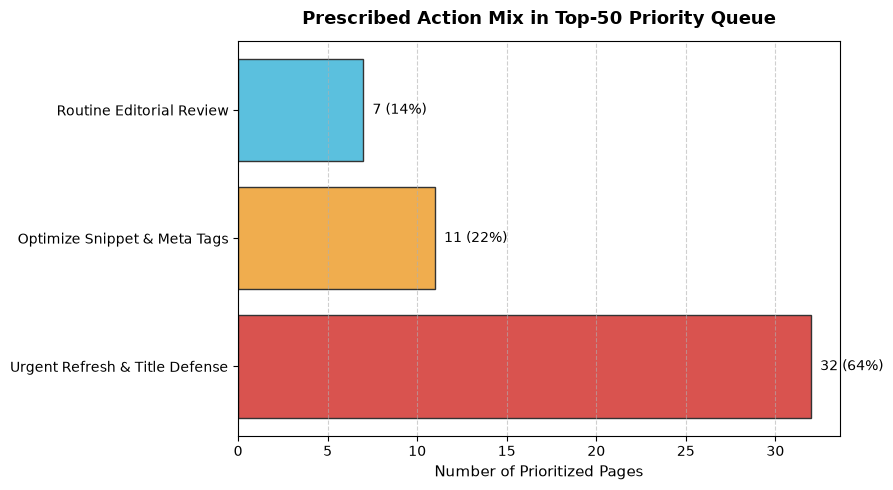

✅ Exported: C:\Users\akbarprdna\AppData\Local\Temp\fr-akbar\work\figures\action_mix.png


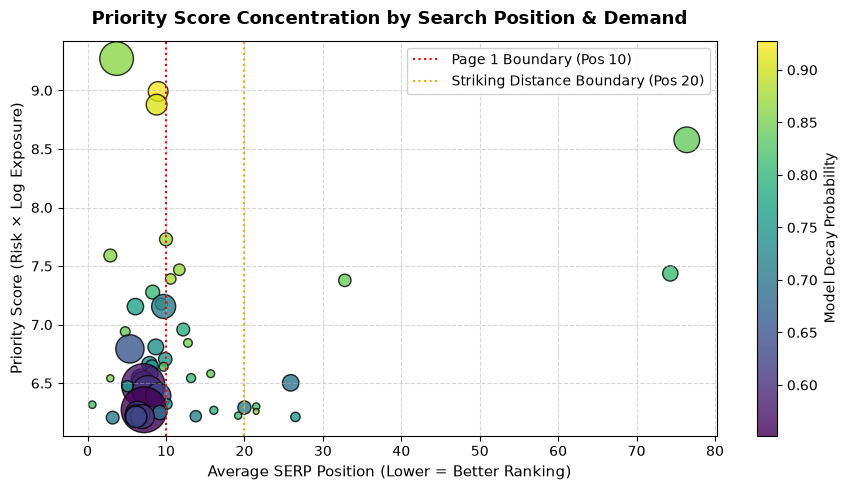

✅ Exported: C:\Users\akbarprdna\AppData\Local\Temp\fr-akbar\work\figures\priority_vs_position.png
✅ Exported: C:\Users\akbarprdna\AppData\Local\Temp\fr-akbar\work\outputs\playbook_summary.json


In [5]:
# 5. Export Ranked Queue, Visualizations, and Summary JSON
from pathlib import Path
import os
import json
import matplotlib.pyplot as plt

# Dynamically resolve output directories whether running from root or work/notebooks
curr = Path.cwd()
if (curr / "data/raw").exists():
    repo_root = curr
elif (curr.parent.parent / "data/raw").exists():
    repo_root = curr.parent.parent
elif (curr.parent / "data/raw").exists():
    repo_root = curr.parent
else:
    repo_root = curr

output_dir = repo_root / "work" / "outputs"
figures_dir = repo_root / "work" / "figures"
output_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)

# 1. Export Ranked Action Queue CSV
export_cols = [
    "rank", "content_id", "client_id", "impressions_90d", "avg_position", "ctr",
    "days_since_last_update", "word_count", "model_decay_prob", "priority_score",
    "reason_codes", "suggested_action", "governance_tier"
]
csv_path = output_dir / "action_queue_top50.csv"
top50_queue[export_cols].to_csv(csv_path, index=False)
print(f"✅ Exported: {csv_path} ({len(top50_queue)} prioritized pages)")

# 2. Figure 1: Action Mix Distribution
plt.figure(figsize=(9, 5))
action_counts = top50_queue["suggested_action"].value_counts()
colors = ["#d9534f", "#f0ad4e", "#5bc0de", "#5cb85c", "#6c757d"][:len(action_counts)]
bars = plt.barh(action_counts.index, action_counts.values, color=colors, edgecolor="#333333")
plt.title("Prescribed Action Mix in Top-50 Priority Queue", fontsize=13, pad=12, fontweight="bold")
plt.xlabel("Number of Prioritized Pages", fontsize=11)
plt.grid(axis="x", linestyle="--", alpha=0.6)
for bar in bars:
    width = bar.get_width()
    plt.text(width + 0.5, bar.get_y() + bar.get_height()/2, f"{int(width)} ({width/50:.0%})", va="center", fontsize=10)
plt.tight_layout()
fig1_path = figures_dir / "action_mix.png"
plt.savefig(fig1_path, dpi=300)
plt.show()
print(f"✅ Exported: {fig1_path}")

# 3. Figure 2: Priority Score vs Average Position
plt.figure(figsize=(9, 5))
plt.scatter(
    top50_queue["avg_position"],
    top50_queue["priority_score"],
    c=top50_queue["model_decay_prob"],
    cmap="viridis",
    s=top50_queue["impressions_90d"] / 80,
    alpha=0.8,
    edgecolors="black"
)
plt.axvline(10, color="red", linestyle=":", label="Page 1 Boundary (Pos 10)")
plt.axvline(20, color="orange", linestyle=":", label="Striking Distance Boundary (Pos 20)")
plt.colorbar(label="Model Decay Probability")
plt.title("Priority Score Concentration by Search Position & Demand", fontsize=13, pad=12, fontweight="bold")
plt.xlabel("Average SERP Position (Lower = Better Ranking)", fontsize=11)
plt.ylabel("Priority Score (Risk × Log Exposure)", fontsize=11)
plt.legend(loc="upper right", framealpha=0.9)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
fig2_path = figures_dir / "priority_vs_position.png"
plt.savefig(fig2_path, dpi=300)
plt.show()
print(f"✅ Exported: {fig2_path}")

# 4. Export Playbook Summary JSON
playbook_summary = {
    "total_queue_items": len(top50_queue),
    "test_clients_evaluated": len(test_clients),
    "test_set_base_rate": round(float(df_test["is_declining_label"].mean()), 3),
    "precision_at_50_pure_model": round(float(df_test.sort_values("model_decay_prob", ascending=False).head(50)["is_declining_label"].mean()), 3),
    "precision_at_50_exposure_weighted": round(float(top50_queue["is_declining_label"].mean()), 3),
    "median_impressions_top50": int(top50_queue["impressions_90d"].median()),
    "action_distribution": action_counts.to_dict(),
    "governance_distribution": top50_queue["governance_tier"].value_counts().to_dict(),
    "reproducibility_seed": 42,
    "status": "validated_for_capstone_paper"
}
json_path = output_dir / "playbook_summary.json"
with open(json_path, "w", encoding="utf-8") as f:
    json.dump(playbook_summary, f, indent=2)
print(f"✅ Exported: {json_path}")

## Self-check

Before you submit, confirm each line honestly:

- [x] Every section above is filled — markdown thinking AND the code that backs it
- [x] The notebook runs top to bottom with no errors (Runtime → Run all)
- [x] No client names, URLs, or private queries anywhere
- [x] My claims use careful words: observed, measured, directional, decision-support
- [x] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.